# Perceptron trick

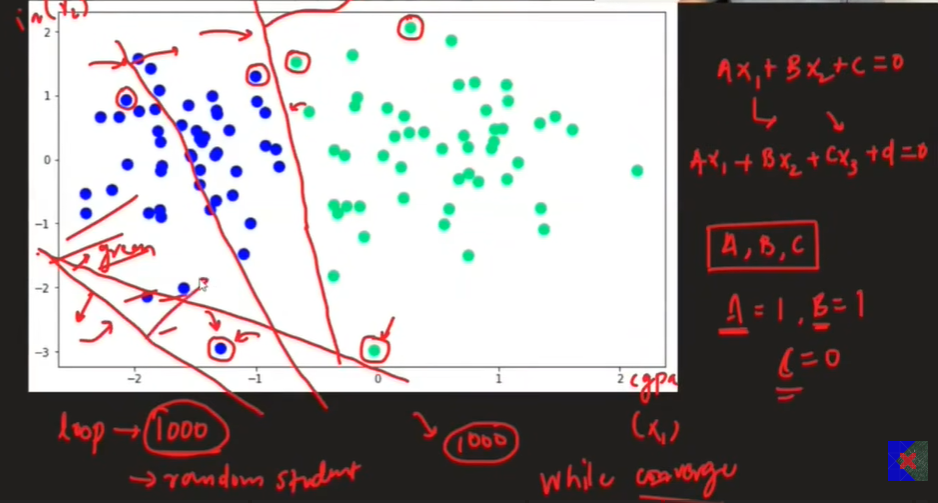

genrerally amora single feature er jonno  y = mx + c use kori; but multi feature er jonno y = w1x1 + w2x2 + b eita logistics regresion e general form hisebe use kori but arekta ase
Ax1 + Bx2 + c = 0 eita use kori ; y = mx + c linear regression e eita use kori r logistics regression e Ax1 + Bx2 + c = 0 eita use kori.
eikhane x1 = cgpa; x2 = iq; c = intercept. eikhane jehatu ami proper akta line khujbo tar mane ami A,B,C er man ber korbo. so the main objective is, ei A , B and C er amn value khuja
jate ei ei dataset er opor jei class ase take properly classify korte pari. eikhane dekhbo perceptron trick kivabe kaj kore


perceptron trick:
ami A,B and C er random value diya start kori A = 1, B = 1 , C=0; eite akta random line draw hobe, jahatu class amar duita placement hobe kina. jeita green and blue boltesi 
green = hobe blue = hobe na. oi line er dan pashe point gulo jodi green hoy hobe and bam pashe jodi blue hoy hobe na. and eita line thik ase but line er dane jodi blue thake jeita bame thakar kotha tahole oi position theke line ke tranform korbo A,B and C er man change kore

Question is: koto bar korbo?
-> eita 1000 bar ba 10000 bar loop caliya dekhte pari je oi point gulo sotil vabe classify hoise kina. 2nd way hocche
-> while converange  er maddhome eita totobar loop colbe jotokkhon porjontto na convergence 0 asbe. 

Question how this convergence work?
-> below

# How ta label region?

bujbo ki kore line er opore thakbe placement hobe and niche hobe na. ei jonno akta tool ase
- Desmos

1. How to identify the positive region and the negative region
- it have a tools called "Desmos" 

# Transformation

 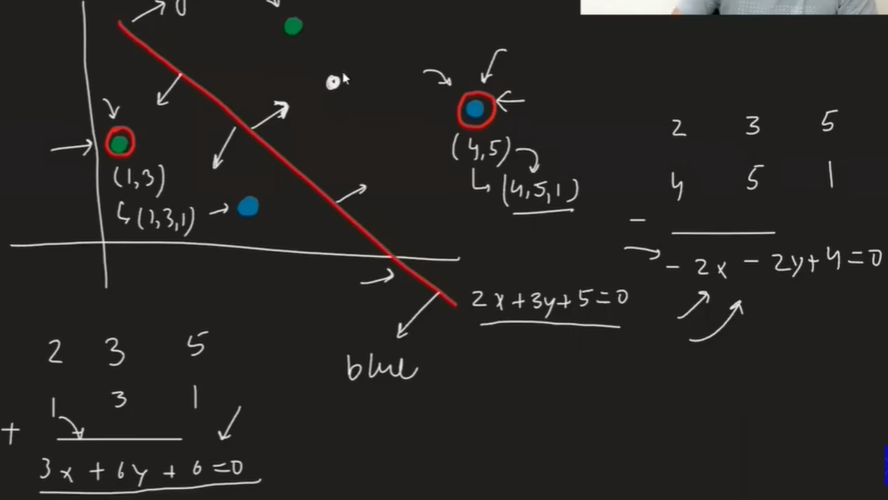

 jodi akta negative point positive rigion e thake, tahole tar coordinate er moddhe last e 1 add kore, line er coef theke minus korbo. 
 - r amora jani c er man komle line opore jabe r opore gele negative point er right place pabe tai minus korbo

 And jodi akta positive point negative rigion e thake, tahole tar coordinate er moddhe last 1 add kore, line er coef sathe add korbo. 
 - ete positive point opore cole asbo and right form a asbo

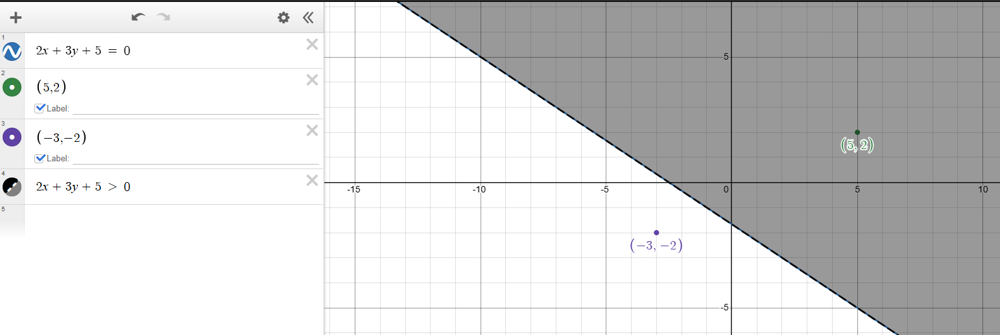

2x + 3y + 5 = 0
eikhane (5,2) negative region e thakar kotha ase positive rigion e, tai coef (2,3,5) theke coordinate er sath 1 add(5,2,1) kore minus korte hobe
- -3x + y 3 = 0


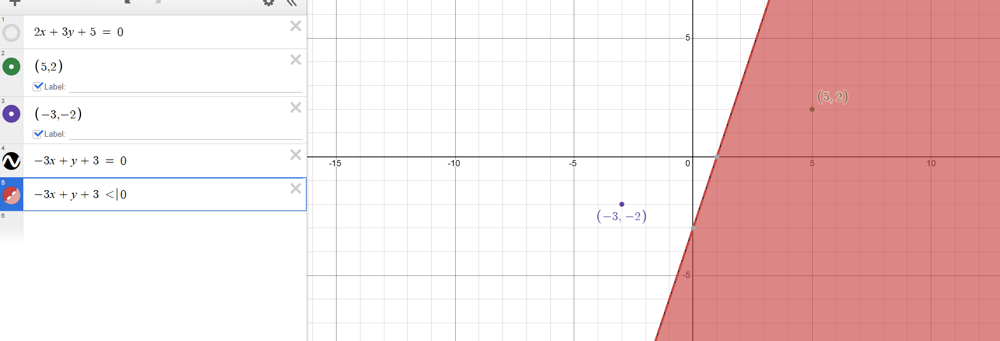

# Note

amora ato boro transformation apply kori na. instead of this
- amora learning rate er sathe new coordinate multiply kore ager ta theke minus kori. and ei learning rate = 0.01/0.1 hote pare

coef = coef - n*coordinate




# Algorithms

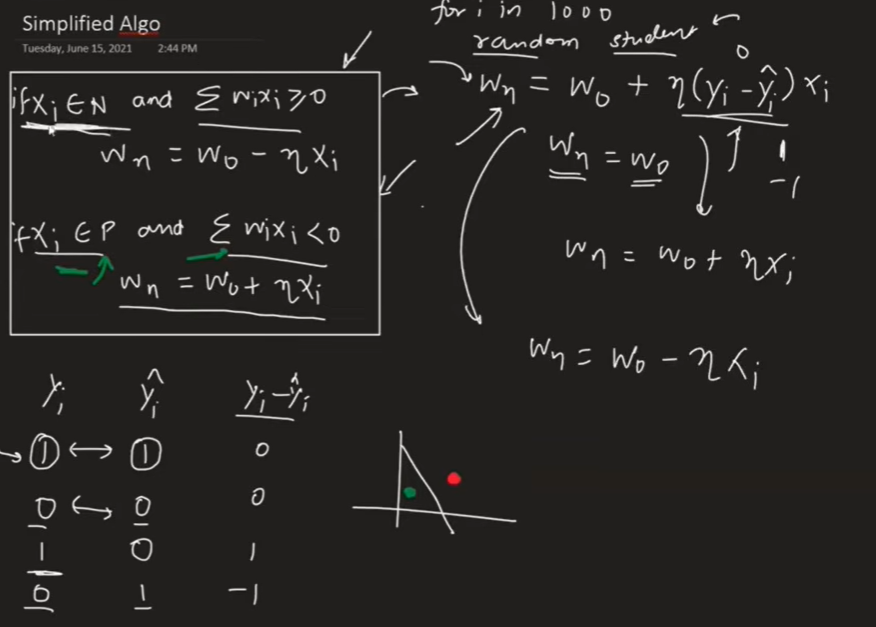

# simplified algo

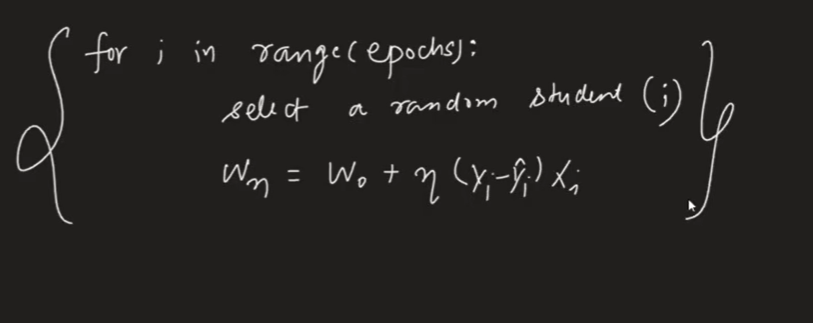

In [4]:
from sklearn.datasets import make_classification
import numpy as np
import matplotlib.pyplot as plt


In [3]:
X, y = make_classification(n_samples=100, n_features=2, n_informative=1, n_redundant=0, n_classes=2, n_clusters_per_class=1, random_state=41,
                           hypercube=False, class_sep=10)

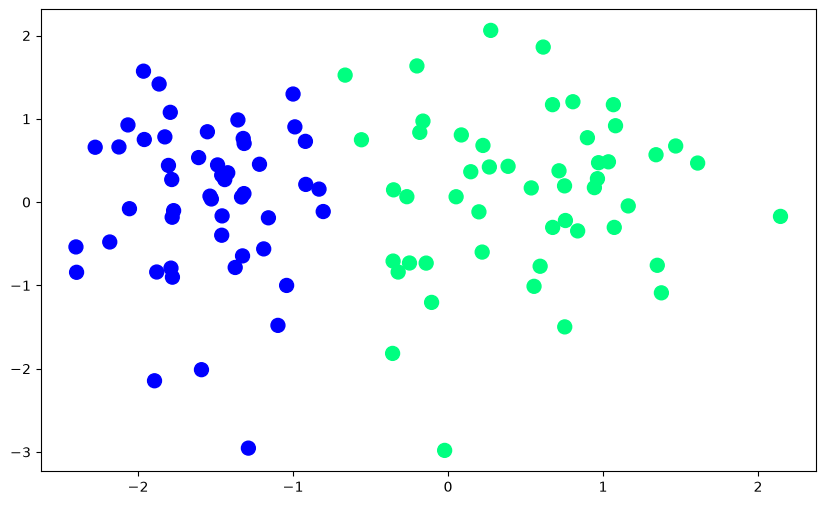

In [5]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1], c=y, cmap='winter', s=100)

In [13]:
def perceptron(X,y):
    X = np.insert(X,0,1,axis=1)
    weight = np.ones(X.shape[1])
    lr = 0.1

    for i in range(1000):
        j = np.random.randint(0,100)
        y_hat = step(np.dot(X[j],weight))
        weight = weight + lr*(y[j] - y_hat)*X[j]

    return weight[0], weight[1:]  

In [14]:
def step(z):
    return 1 if z>0 else 0

In [15]:
intercept_, coef = perceptron(X,y)

In [16]:
print(coef)
print(intercept_)

[1.29642255 0.20150907]
0.9


In [17]:
m = -(coef[0]/coef[1])
b = -(intercept_/coef[1])

In [21]:
x_input = np.linspace(-3,3,100)
y_input = m*x_input + b

(-3.0, 2.0)

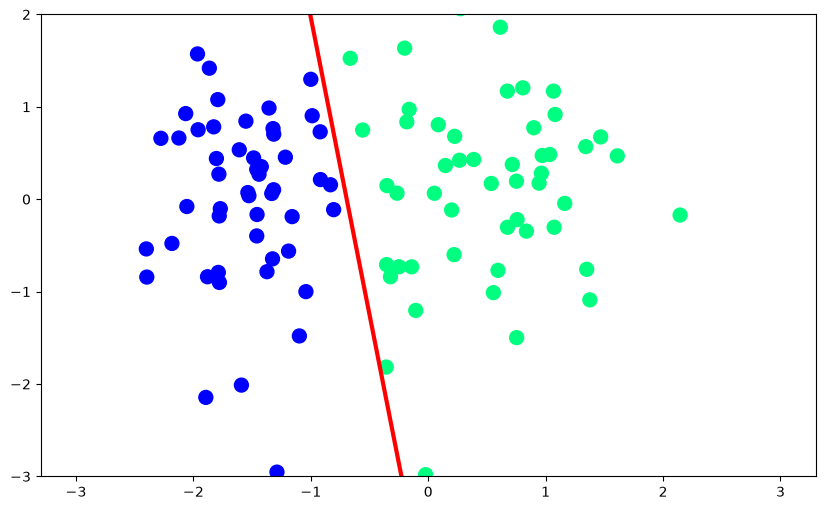

In [22]:
plt.figure(figsize=(10,6))
plt.plot(x_input, y_input, color='red', linewidth = 3)
plt.scatter(X[:,0],X[:,1], c=y, cmap='winter', s=100)
plt.ylim(-3,2)

# Animation

In [38]:
def perceptron(X,y):

    m = []
    b = []


    X = np.insert(X,0,1,axis=1)
    weight = np.ones(X.shape[1])
    lr = 0.1

    for i in range(200):
        j = np.random.randint(0,100)
        y_hat = step(np.dot(X[j],weight))
        weight = weight + lr*(y[j] - y_hat)*X[j]

        m.append(-(weight[1]/weight[2]))
        b.append(-(weight[0]/weight[2]))

    return m,b 

In [39]:
m,b = perceptron(X,y)

In [43]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(9, 5))

x_i = np.arange(-3, 3, 0.1)

ax.scatter(X[:, 0], X[:, 1], c=y, cmap="winter", s=100)

line, = ax.plot(
    x_i,
    m[0] * x_i + b[0],
    "r-",
    linewidth=2
)

ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)

def update(i):
    line.set_ydata(m[i] * x_i + b[i])
    ax.set_xlabel(f"Epoch {i + 1}")
    return line,

anim = FuncAnimation(
    fig,
    update,
    frames=len(m),
    interval=100,
    blit=False,
    repeat=True
)

display(HTML(anim.to_jshtml()))

<IPython.core.display.Javascript object>